In [1]:
# Cell 1: Clean Imports
import matplotlib.pyplot as plt
from pathlib import Path
# Custom package modules
from behavior_fw.utils.psth import extract_experiment_psth
from behavior_fw.analysis.calc_velocities import get_velocities
from behavior_fw.visualization.plot_density import (
    plot_dynamic_cartesian_densities,
    plot_dynamic_polar_densities,
)
from behavior_fw.visualization.plot_psth import (
    plot_condition_psth_summary,
    plot_single_experiment_psth,
)
from behavior_fw.visualization.plot_trajectory import plot_single_fly_trajectory

In [2]:
from behavior_fw.io.load_dataset import load_experiment_dataset

path_dir_data = Path("/home/athira/CF/PhD/Data")
# path_dir_dataset  = path_dir_data / "FW_Darkness_Bonsai_08082026" 
path_dir_dataset  = path_dir_data / "LocalSearch_OptoCL" 


In [3]:
from behavior_fw.core.dataset import create_experiments_metadata, select_exp_condition

df_metadata = create_experiments_metadata(path_dir_dataset)
df_metadata


,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
0,20260814_165206_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,165206,2026-08-14 16:52:06,Gr43a,OptoCL,ATR
1,20260814_171722_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260814,171722,2026-08-14 17:17:22,Gr43a,OptoCLReplay,ATR
2,20260815_095930_Gr43a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,095930,2026-08-15 09:59:30,Gr43a,OptoCL,ATR
3,20260815_102821_Gr43a_OptoCLReplay_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,102821,2026-08-15 10:28:21,Gr43a,OptoCLReplay,ATR
4,20260815_110148_Gr43a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260815,110148,2026-08-15 11:01:48,Gr43a,OptoCL,NR
...,...,...,...,...,...,...,...,...
116,20260927_214323_Gr5a_OptoCL_ATR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,214323,2026-09-27 21:43:23,Gr5a,OptoCL,ATR
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR


In [27]:
df_Gr43a_ATR_CL = select_exp_condition(df_metadata, genotype="Gr5a", protocol="OptoCL", medium="NR")
df_Gr43a_ATR_CL

,folder_name,folder_path,date,time,datetime,genotype,protocol,medium
110,20260927_182320_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,182320,2026-09-27 18:23:20,Gr5a,OptoCL,NR
112,20260927_193739_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,193739,2026-09-27 19:37:39,Gr5a,OptoCL,NR
114,20260927_202711_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,202711,2026-09-27 20:27:11,Gr5a,OptoCL,NR
115,20260927_211747_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,211747,2026-09-27 21:17:47,Gr5a,OptoCL,NR
117,20260927_220910_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,220910,2026-09-27 22:09:10,Gr5a,OptoCL,NR
118,20260927_223457_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,223457,2026-09-27 22:34:57,Gr5a,OptoCL,NR
119,20260927_225846_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,225846,2026-09-27 22:58:46,Gr5a,OptoCL,NR
120,20260927_232714_Gr5a_OptoCL_NR,/home/athira/CF/PhD/Data/LocalSearch_OptoCL/Gr...,20260927,232714,2026-09-27 23:27:14,Gr5a,OptoCL,NR


In [ ]:
# 1. Standard fast run (Loads from cache if available, calculates if missing)
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

# 2. (Optional) Force re-computing velocities for all flies from raw tracking:
# dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0, force_recompute=True)

In [17]:
# Loads processed CSVs if they exist, or calculates LOWESS once and caches to disk
dataset = load_experiment_dataset(df_Gr43a_ATR_CL, fps=60.0)

print(f"Loaded {len(dataset)} flies into memory!")
print("Columns in df_track:", dataset[0]["df_track"].columns.tolist())

Loaded 15 flies into memory!
Columns in df_track: ['Index', 'X_cal', 'Y_cal', 'ori_angle_cal', 'X_px', 'Y_px', 'ori_angle', 'LowResTimestampTick', 'LowResFrameNumber', 'HighResFrameNumber', 'X', 'Y', 'LEDstate', 'Vf_smooth', 'Vs_smooth', 'Vr_smooth', 'Vt_smooth']


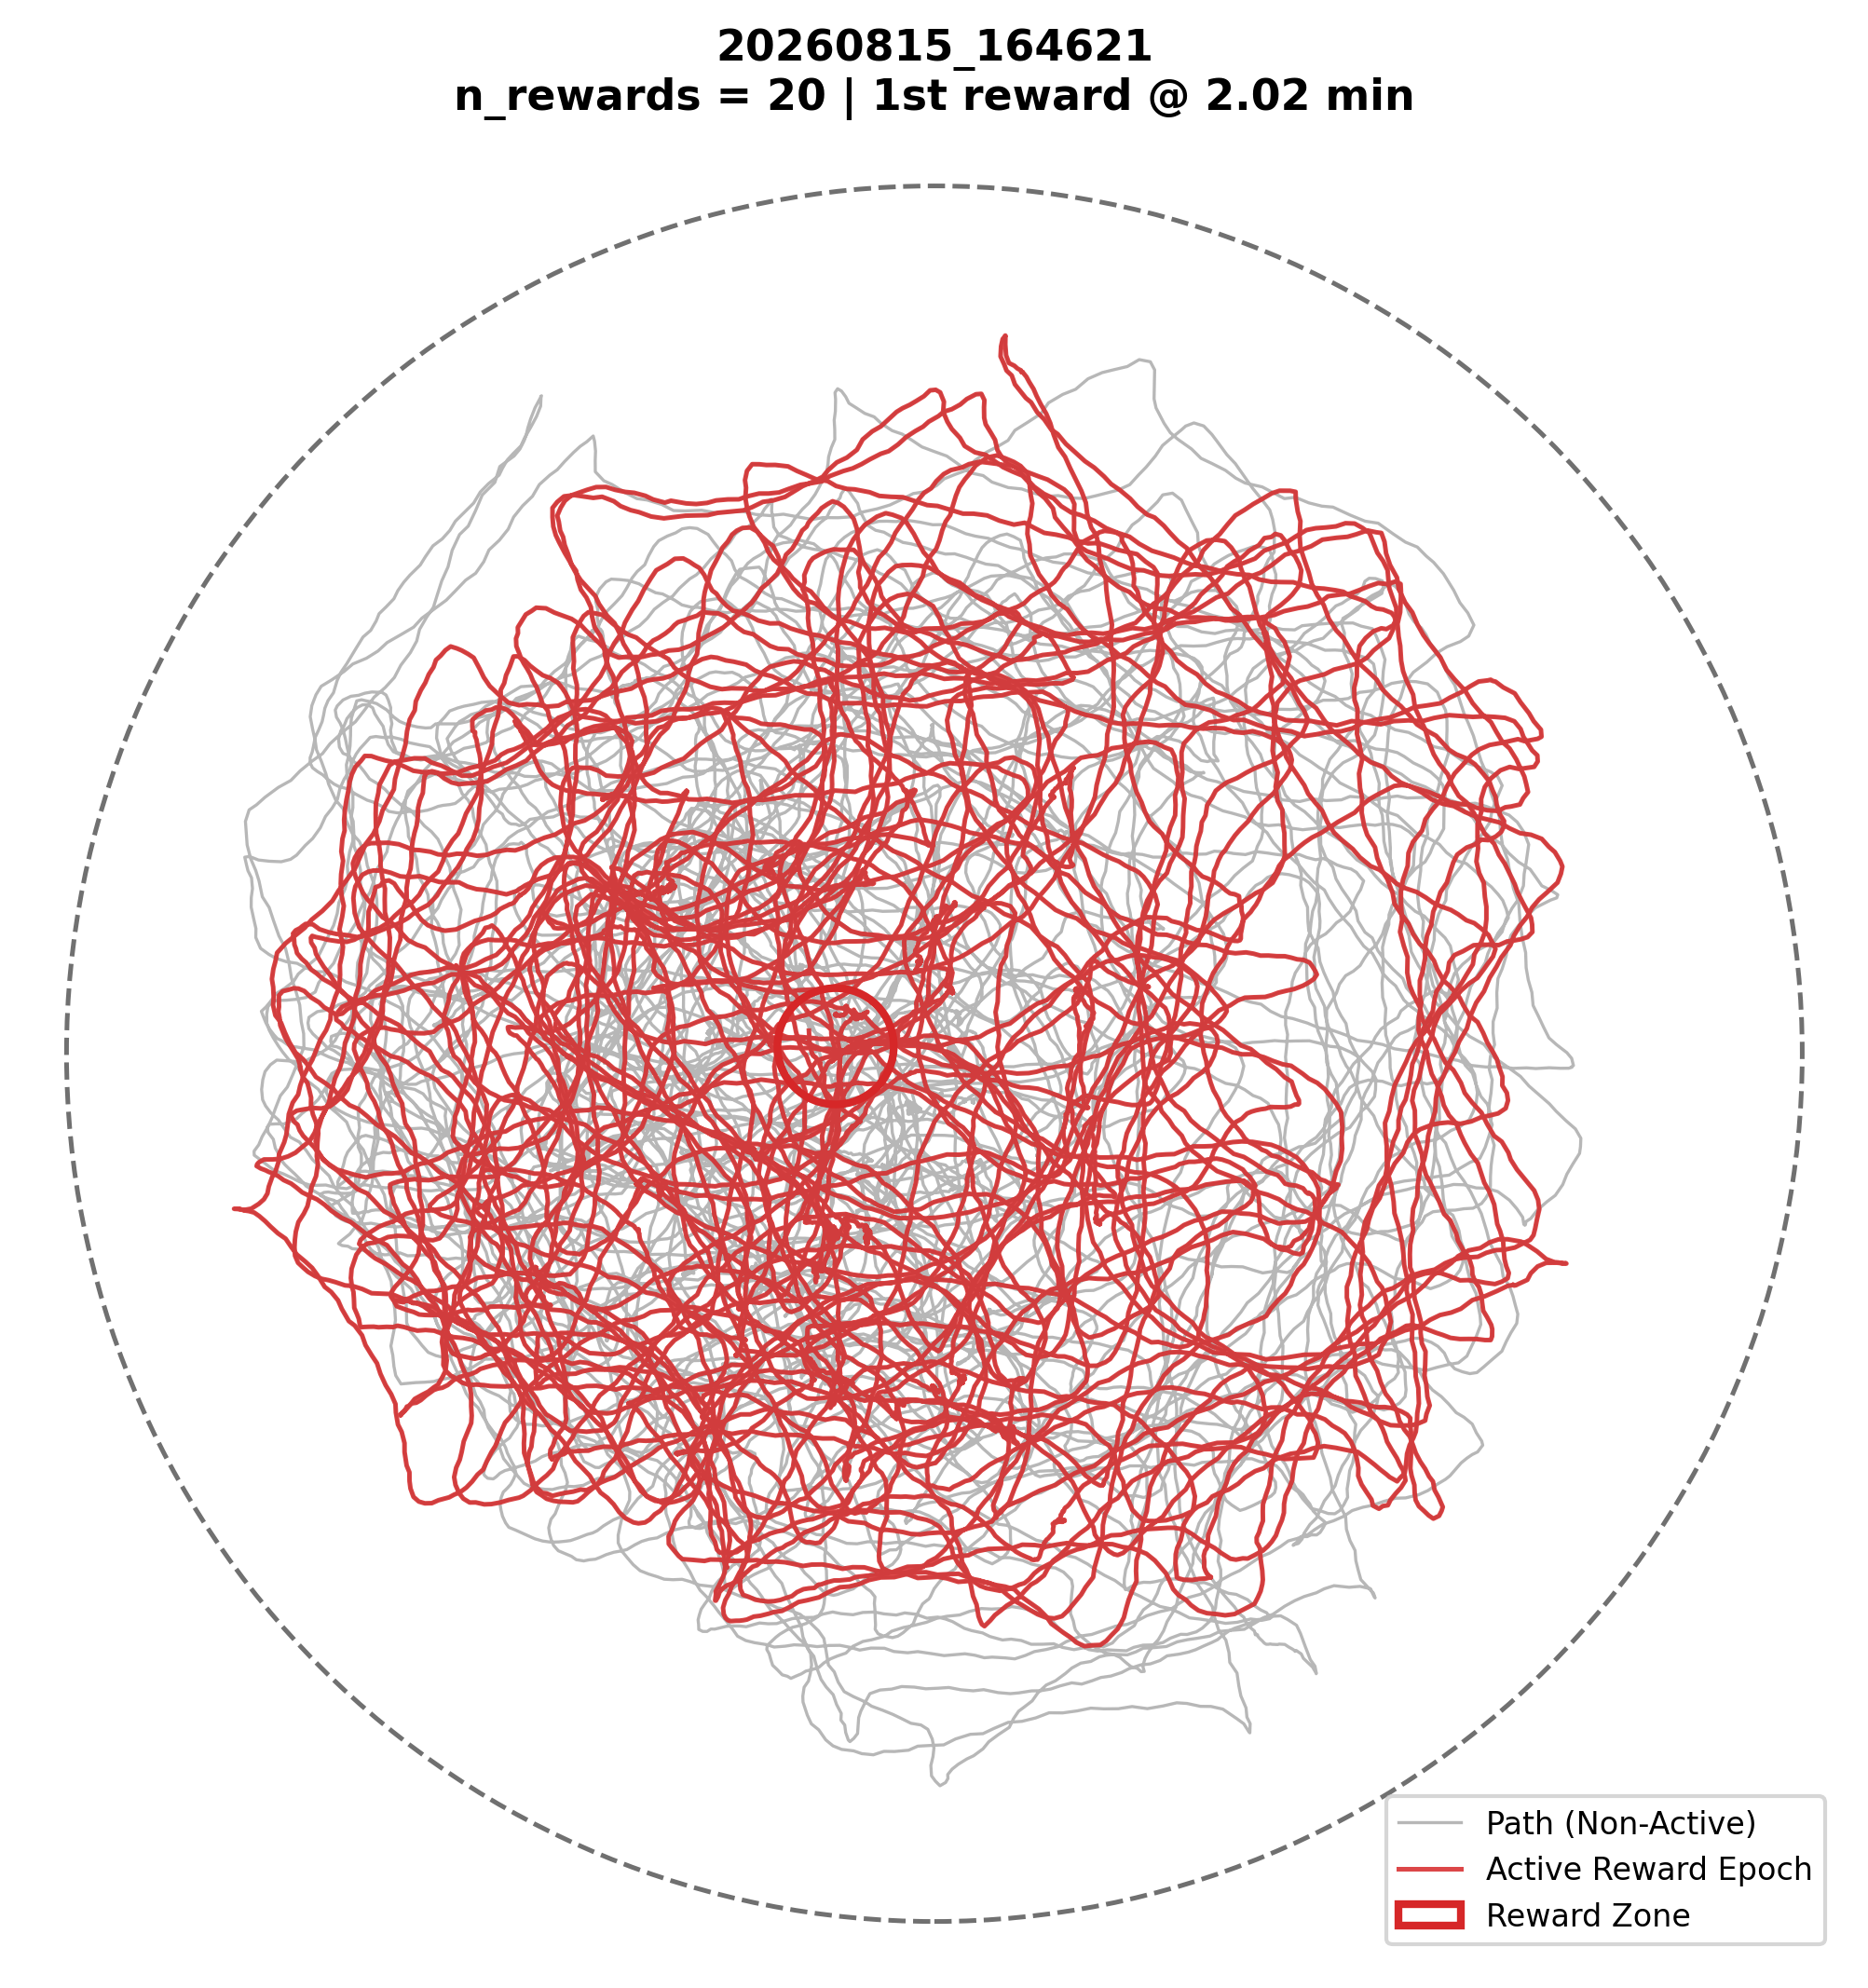

In [24]:
exp = dataset[4]  # Pick first fly

fig, ax = plot_single_fly_trajectory(exp, arena_r=45.0, fps=60.0)
plt.show()

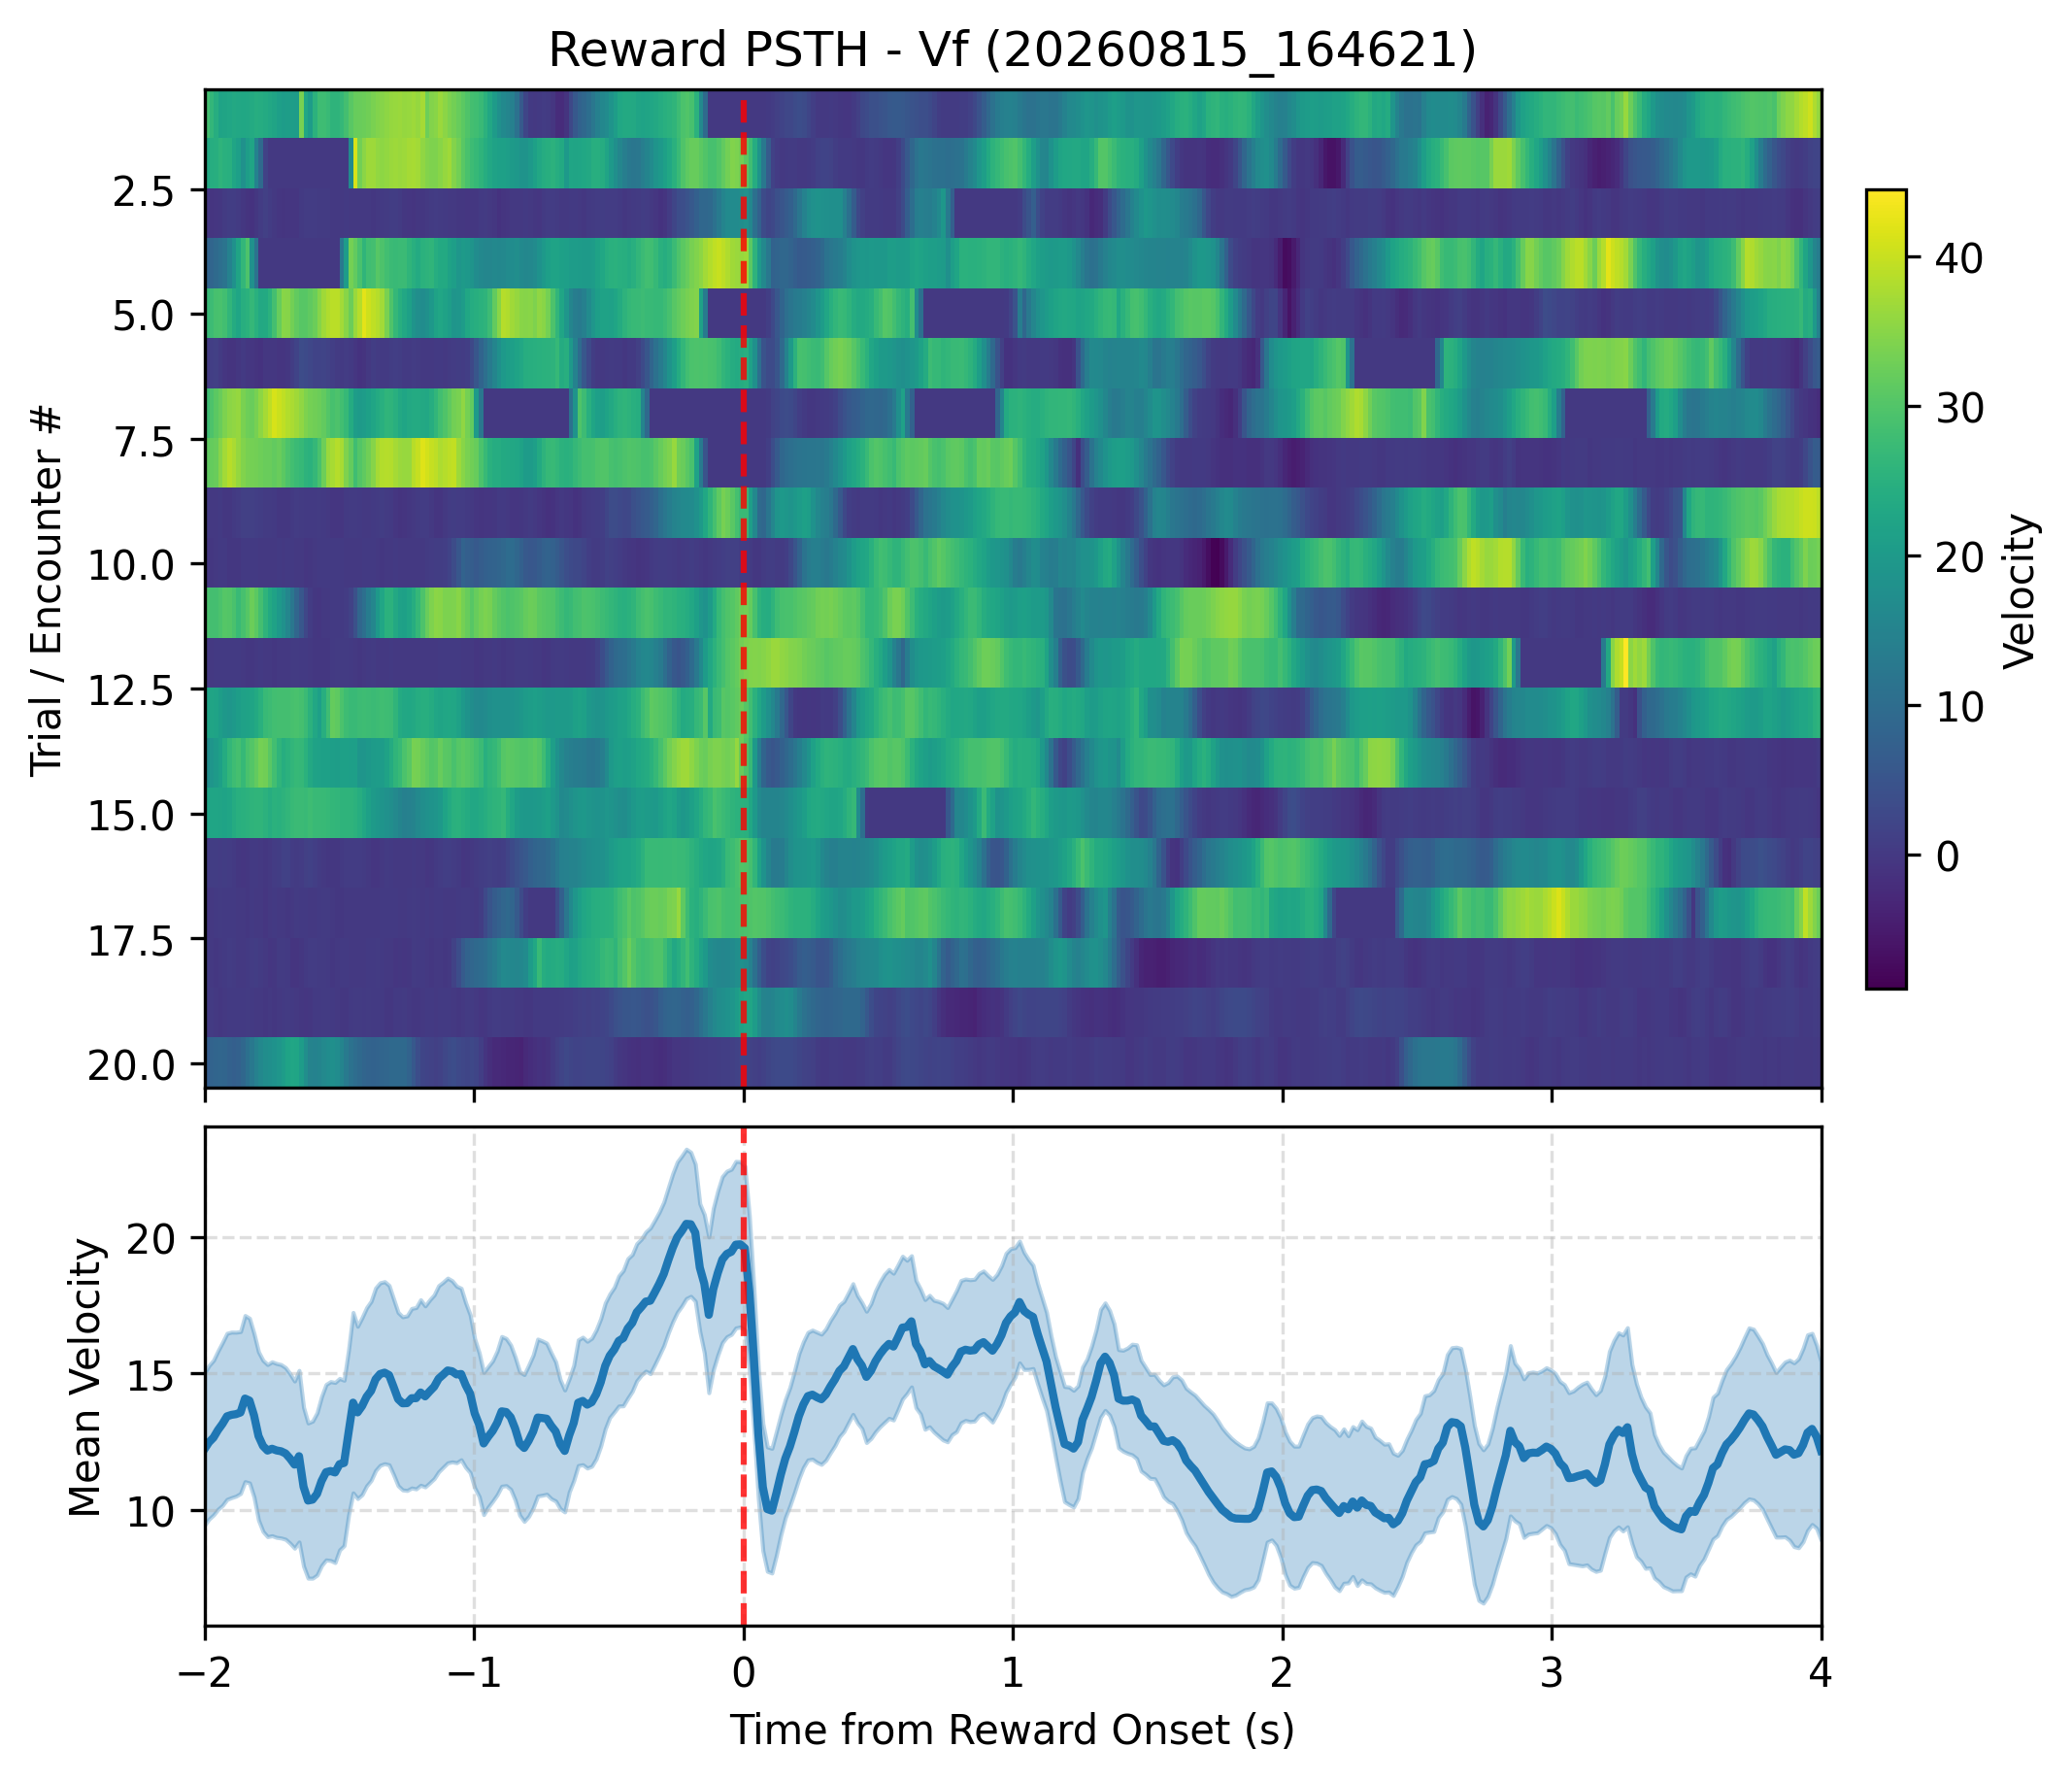

In [25]:
# Extract reward-centered windows (-2s to +4s)
psth_dict = extract_experiment_psth(
    exp, metrics=["Vf_smooth", "Vr_smooth"], window_sec=(-2.0, 4.0)
)

# Plot Trial Heatmap + Average Speed Response
fig, axes = plot_single_experiment_psth(
    psth_dict, metric="Vf_smooth", title=exp["uid"]
)
plt.show()

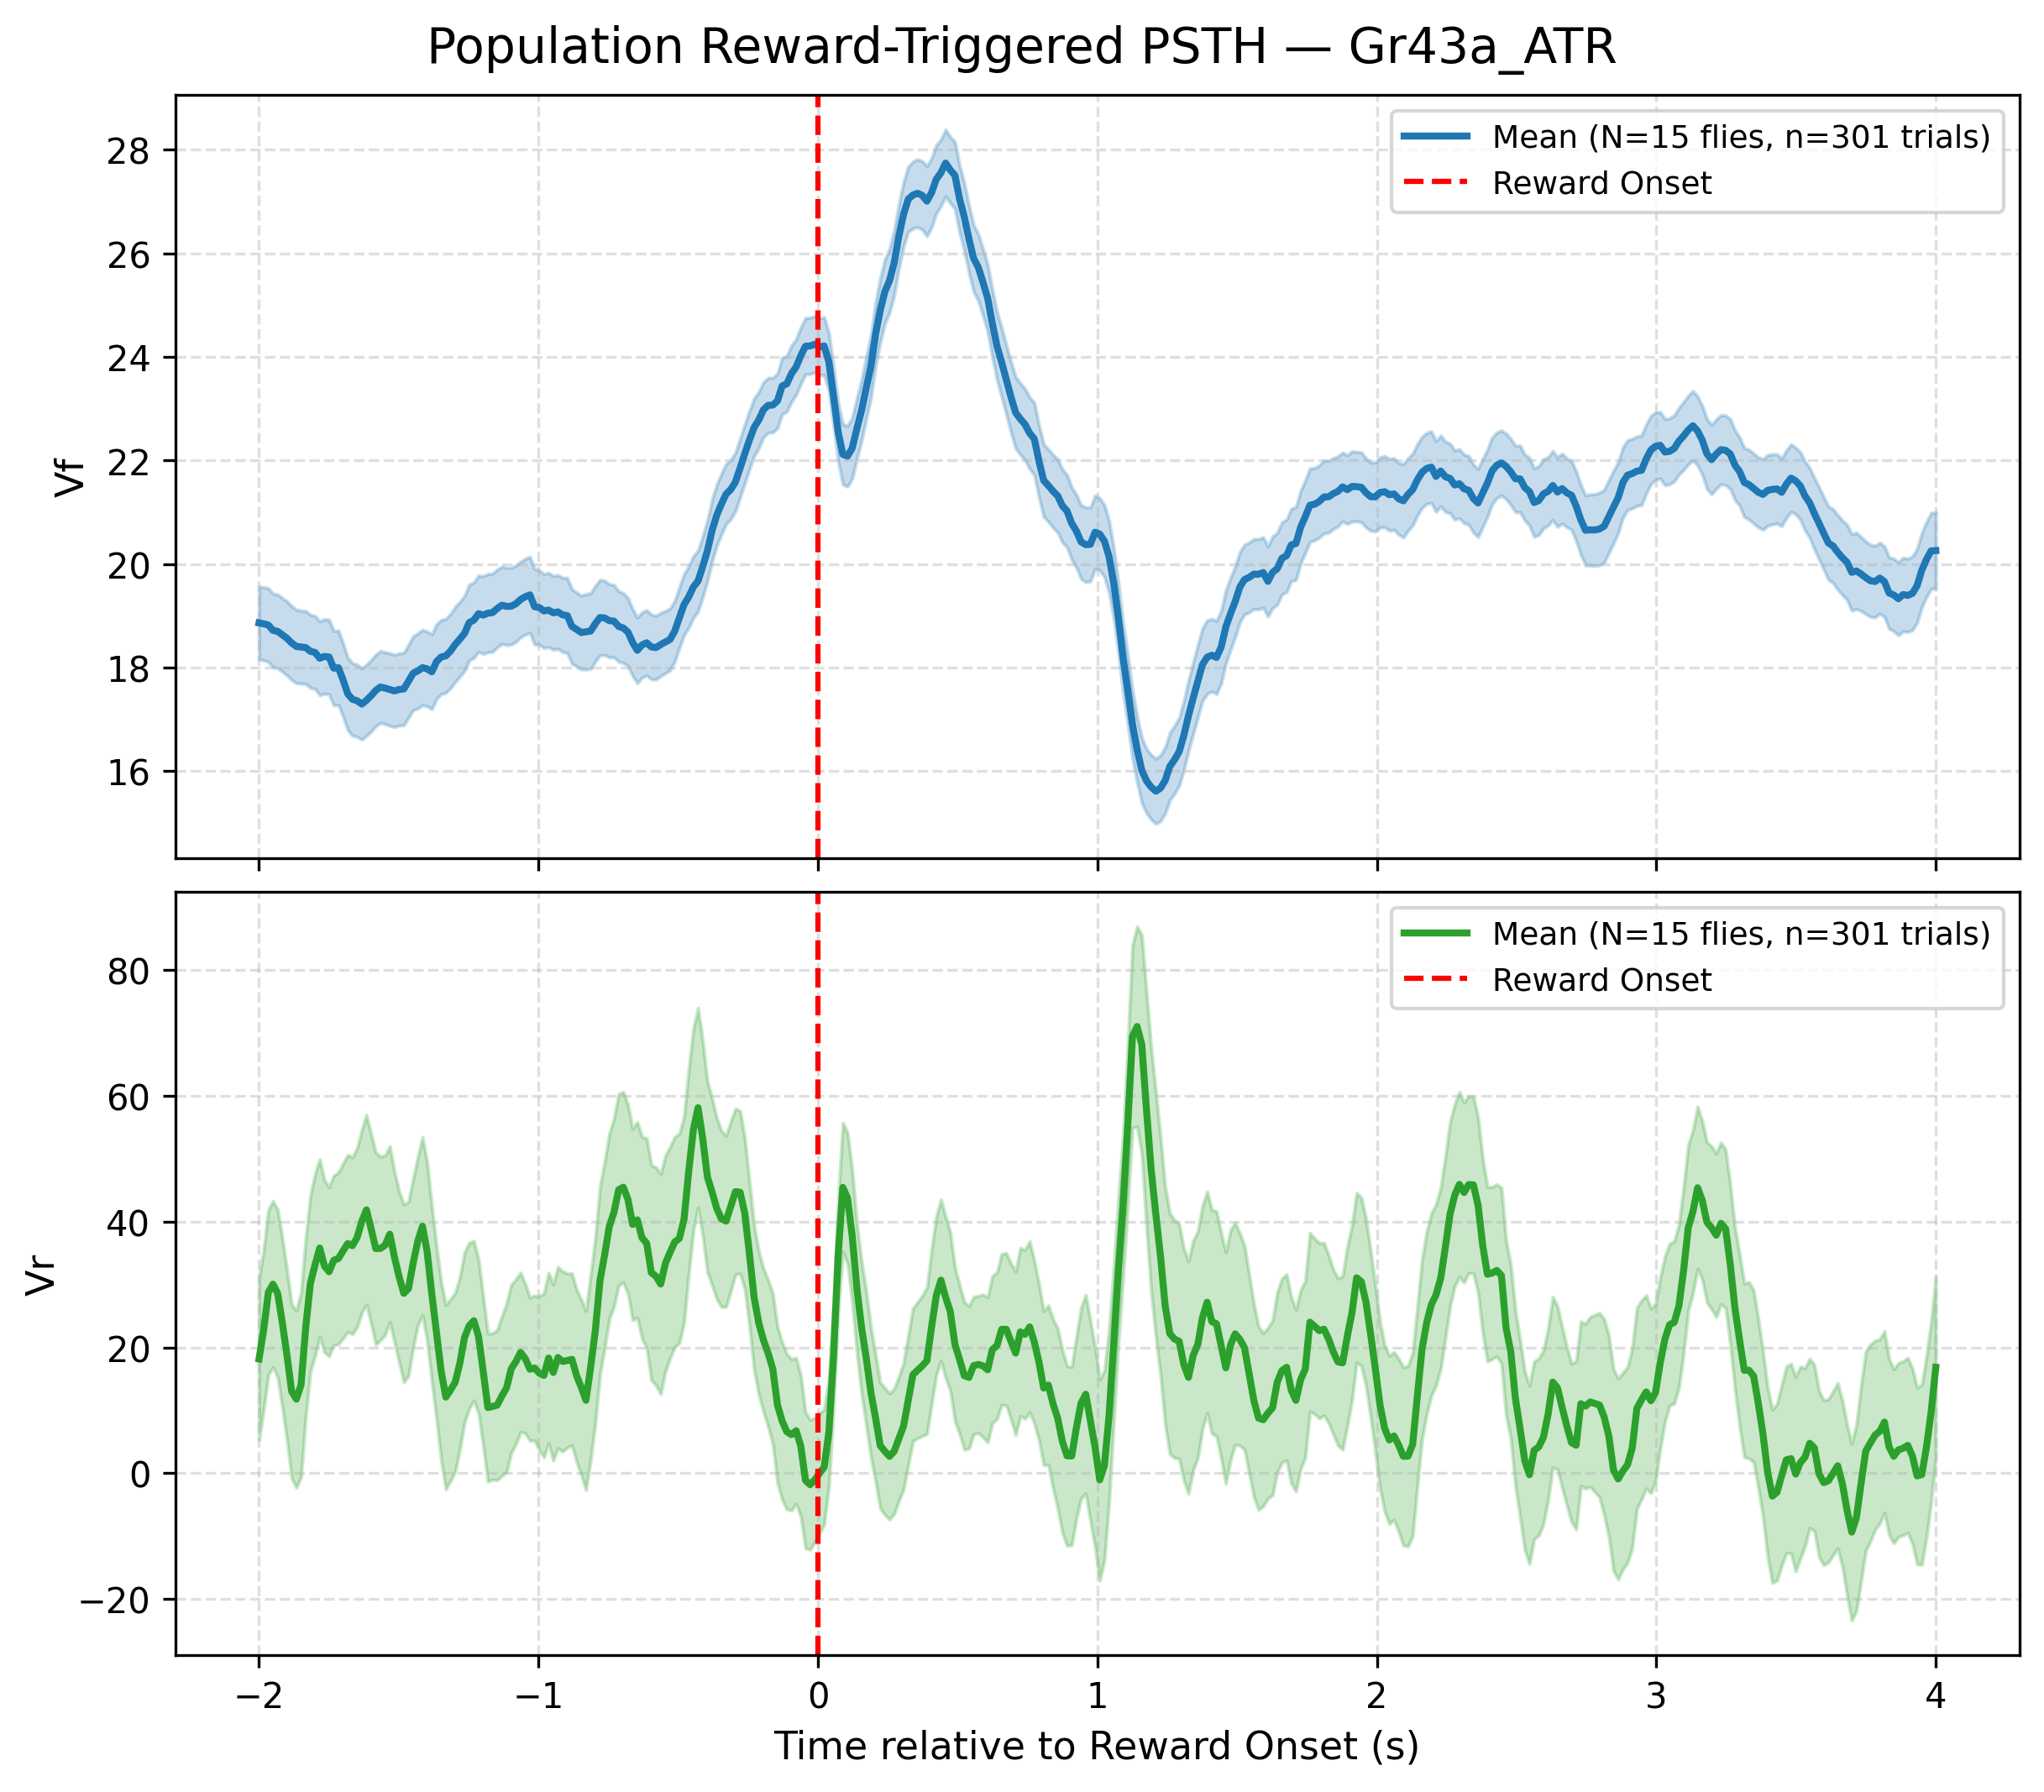

In [26]:
fig, axes = plot_condition_psth_summary(
    dataset,
    condition_name="Gr43a_ATR",
    metrics=["Vf_smooth", "Vr_smooth"],
    window_sec=(-2.0, 4.0),
)
plt.show()